In [1]:
from rcsbapi.data import DataQuery
import inspect
from CIFcurator import cifcurator_io
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

/opt/anaconda3/envs/CIFcurator/lib/python3.14/site-packages/rcsbapi/data/data_query.py:25: RuntimeWarning: 
When working in Jupyter with Python 3.14+, `.exec()` calls must be explicitly awaited, e.g.:
    from rcsbapi.data import DataQuery
    query = DataQuery(input_type="entries", input_ids=[...], return_data_list=[...])
    results = await query.exec()

  warn(


# Summary of PDB dataset (RCSB Data API)

## What is the goal of this notebook?

This notebook creates the same summary as 'Analysis.SummaryPDBDataset', but it takes the information from the RCSB PDB Data API instead of the CIF files. The files downloaded from the wwPDB archive (biological assemblies) often do not include the organism, the deposition date or the resolution, so reading them from the CIFs leaves gaps.

The notebook only uses the CIF file names to know which PDB IDs are in the dataset. Users need to create a 'pdblist.txt' with the list of CIFs that will be included in the summary, and specify the directories where the CIFs are stored and where the created files will be stored. An internet connection is needed.

In the first step, a pandas dataframe is populated with the info returned by the RCSB API, one row per CIF file. The info in the dataframe is then written as a csv file. Users choose between the shortened or full name of the organisms with the `organism_name` option.
The shortened version only displays the first two words of the organism's name.

(Example - [Full name: 'Leptospira interrogans serovar Icterohaemorrhagiae str. RGA']  --- [Short name: 'Leptospira interrogans'])

In a second step, we create an image with the plots summarizing the data in the dataframe. Four plots are included, a histogram of the resolution of the structures, a histogram of the year in which the structures were deposited, a histogram of the methods used to solve the structures, and a histogram of the organism of origin of the molecule in the structure. The image with the four plots is saved as a pdf.



## How to create the 'pdblist.txt'

To create the 'pdblist.txt' run this line within the terminal **in the 'raw_bank' directory**:

>ls | grep cif > pdblist.txt

Or run the cell below:

In [2]:

PROJDIR="TIM"
!cd ./$PROJDIR/raw_bank/ && ls | grep cif > pdblist.txt && tail pdblist.txt

pdb_00008w06+02.cif
pdb_00008w06+03.cif
pdb_00008w06+04.cif
pdb_00008w08+01.cif
pdb_00009f69+01.cif
pdb_00009ffc+01.cif
pdb_00009qm7+01.cif
pdb_00009qus+01.cif
pdb_00009quu+01.cif
pdb_00009r6m+01.cif


## Define functions

In [3]:
def pdbid_from_filename(cif_name):
    """
        Returns the PDB ID from a CIF file name.

        Assembly files are named PDBID+NN.cif (pdb_00001aw1+01.cif), full entries PDBID.cif (pdb_00001aw1.cif).
        Legacy names (1aw1+01.cif) are also accepted.

        Parameters
        ----------
        cif_name : (str)
            The name of the CIF file.

        Returns
        ----------
        str
            The PDB ID, e.g. 'pdb_00001aw1'.
    """
    pdb_id = cif_name.strip()
    if pdb_id.endswith('.cif'):
        pdb_id = pdb_id[:-4]
    return pdb_id.split('+')[0]


def legacy_pdbid(pdb_id):
    """
        Returns the four-character PDB ID in upper case ('pdb_00001aw1' -> '1AW1'), the form returned by the RCSB API.
        Extended IDs that do not start with 'pdb_0000' have no legacy form and are returned in upper case.
    """
    if pdb_id.lower().startswith('pdb_0000'):
        return pdb_id[-4:].upper()
    return pdb_id.upper()


async def query_rcsb(pdb_ids, batch_size=100):
    """
        Retrieves the summary information of a list of PDB entries from the RCSB PDB Data API.

        Parameters
        ----------
        pdb_ids : (list of str)
            The four-character PDB IDs to query.
        batch_size : (int)
            The number of entries requested per query.

        Returns
        ----------
        dict
            The data returned for each entry, keyed by the upper case PDB ID.
    """
    entries = {}
    for start in range(0, len(pdb_ids), batch_size):
        batch = pdb_ids[start:start + batch_size]
        query = DataQuery(
            input_type = 'entries',
            input_ids = batch,
            return_data_list = ['exptl.method',
                                'rcsb_entry_info.resolution_combined',
                                'rcsb_accession_info.deposit_date',
                                'rcsb_primary_citation.year',
                                'polymer_entities.rcsb_entity_source_organism.scientific_name'])
        result = await query.exec()
        if inspect.iscoroutine(result): # newer rcsb-api versions run the query asynchronously in Jupyter
            result = await result
        for entry in result['data']['entries'] or []:
            if entry is not None:
                entries[entry['rcsb_id'].upper()] = entry
    return entries


def format_organisms(entry, organism_name='short'):
    """
        Returns the organisms of the polymer entities of an entry, in upper case and separated by '; '.

        With organism_name='short' only the first two words of each name are kept.
    """
    organisms = set()
    for entity in entry.get('polymer_entities') or []:
        for source in entity.get('rcsb_entity_source_organism') or []:
            name = source.get('scientific_name')
            if not name:
                continue
            if organism_name == 'short':
                name = ' '.join(name.split()[:2])
            organisms.add(name.upper())
    return '; '.join(sorted(organisms))


async def make_pdb_df(read_directory_path, cif_list, organism_name='short'):
    """
        Retrieves information on the entries in a list of CIF files from the RCSB PDB Data API and creates a DataFrame with it.

        This function reads a list of CIF file names from 'pdblist.txt', takes the PDB ID from each file name, and queries
        the RCSB PDB Data API for the organism, resolution, deposition year and experimental method of the entry.
        There is one row per CIF file, so an entry with several assemblies appears once per assembly.
        The function is asynchronous: call it with 'await make_pdb_df(...)'.

        Parameters
        ----------
        read_directory_path : (str)
            The directory path where the CIF files and the list of CIF file names are located.
        cif_list : (str)
            The name of the text file (e.g., 'pdblist.txt') containing the list of CIF file names.
        organism_name : (str)
            'short' for the first two words of the organism names, 'full' for the full names.

        Returns
        ----------
        pandas.DataFrame
            A DataFrame with the following columns
            - 'PDBid' : The PDB ID, taken from the file name before the '+' (e.g. pdb_00001aw1)
            - 'Organism' : Name of organism(s) of the polymer entities in the PDB entry, formatted to the user's choice.
            - 'Resolution (Å)' : Resolution of structure in angstrom, 0 if not found (e.g. NMR structures).
            - 'Year': Year of deposition of PDB entry (year of the primary citation if not found), None if not found.
            - 'Method' : Experimental method used to determine structure listed in PDB entry, or an empty string if not found.
    """
    with open(read_directory_path + cif_list, 'r') as f:
        cif_names = [line for line in f if line.strip()]

    pdb_ids = [pdbid_from_filename(name) for name in cif_names]
    entries = await query_rcsb(sorted(set(legacy_pdbid(pdb_id) for pdb_id in pdb_ids)))

    rows = []
    for pdb_id in pdb_ids:
        entry = entries.get(legacy_pdbid(pdb_id))
        if entry is None:
            print('WARNING: ' + pdb_id + ' was not found in the RCSB PDB')
            rows.append([pdb_id, '', 0, None, ''])
            continue

        organism = format_organisms(entry, organism_name)

        resolution = (entry.get('rcsb_entry_info') or {}).get('resolution_combined')
        resolution = float(resolution[0]) if resolution else 0

        deposit_date = (entry.get('rcsb_accession_info') or {}).get('deposit_date')
        citation_year = (entry.get('rcsb_primary_citation') or {}).get('year')
        if deposit_date:
            year = int(deposit_date[0:4])
        elif citation_year:
            year = int(citation_year)
        else:
            year = None

        exptl = entry.get('exptl') or []
        method = exptl[0]['method'] if exptl else ''

        print(pdb_id, organism, resolution, year, method)
        rows.append([pdb_id, organism, resolution, year, method])

    df = pd.DataFrame(rows, columns = ['PDBid', 'Organism', 'Resolution (Å)', 'Year', 'Method'])
    df['Year'] = df['Year'].astype('Int64')

    return(df)

In [4]:
def summary_plots_pdbs(df, output_directory, output_name):
    """
     Generates and saves a collection of summary plots based on the provided DataFrame.

     Parameters
     ----------
     df : (pandas.DataFrame)
         Dataframe containing summarized information on the PDB dataset
     output_directory : (str)
         The directory path where the generated PDF file with the plots will be saved.
     output_name : (str)
         The name of the project directory which is then used to name the output PDF file.

     Returns
     ----------
     None  
         This function saves the plots as a PDF file in the specified output directory and does not return any values.  
    """
    f = plt.figure(figsize = (32, 48))
    gs = f.add_gridspec(2, 2)
    fs = 40

    #PLOT RESOLUTION
    ax = f.add_subplot(gs[0, 0])
    #sns.boxplot(df['Resolution']).set(title="Resolution (Å)")
    #sns.boxplot(df[df['Resolution'].str.match('N/A')==False]['Resolution'])#.set(title="Resolution (Å)")
    sns.histplot(df['Resolution (Å)']) #.set(title="Resolution (Å)")
    plt.yticks(fontsize = fs)
    plt.xticks(fontsize = fs)
    #plt.title('Resolution (Å)', fontsize=fs)
    ax.xaxis.label.set_size(fs)
    ax.yaxis.label.set_size(fs)
    
    
    #PLOT YEAR
    ax = f.add_subplot(gs[0, 1])
    sort_df = df.sort_values(by = "Year", ascending = True)
    plot = sns.histplot(sort_df['Year'])#.set(title="Year of Publication")
    xtick_loc = plot.get_xticks()
    xtick_labels = plot.get_xticklabels()

        # Set the x-axis ticks

    plt.setp(xtick_labels, rotation = 30, ha = "right")#, fontsize = 'x-small')
    plt.yticks(fontsize = fs)
    plt.xticks(fontsize = fs)
    ax.xaxis.label.set_size(fs)
    ax.yaxis.label.set_size(fs)
    
    #PLOT METHOD
    ax = f.add_subplot(gs[1, 0])
    method_counts = df['Method'].value_counts()

    # Only one unique method
    if len(method_counts) == 1:
        
        plot = sns.barplot(x = method_counts.index, y = method_counts.values, ax=ax)
        plt.xticks(rotation = 0, ha = 'center')
        # Font size customize
        plt.yticks(fontsize = fs)
        plt.xticks(fontsize = fs - 10)  # Adjusted font size for x-axis ticks
        ax.xaxis.label.set_size(fs)
        ax.yaxis.label.set_size(fs)
   
    # Multiple methods
    else:
        plot = sns.histplot(df['Method'])
        xtick_loc = plot.get_xticks()
        xtick_labels = plot.get_xticklabels()
        plt.setp(xtick_labels, rotation=30, ha="right")
        # Font size customize
        plt.yticks(fontsize = fs)
        plt.xticks(fontsize = fs - 20)
        ax.xaxis.label.set_size(fs)
        ax.yaxis.label.set_size(fs)

    #PLOT ORGANISM
    ax = f.add_subplot(gs[1, 1])
    sort_df = df['Organism'].value_counts(ascending = False).rename_axis('Organism').rename('count')
    plot = sns.barplot(x = sort_df.index, y = sort_df.values, order = sort_df.index)

        # Get x-axis tick locations and labels

    xtick_loc = plot.get_xticks()
    xtick_labels = plot.get_xticklabels()

        # Set the x-axis ticks

    plt.setp(xtick_labels, rotation = 30, ha = "right", fontsize = 'x-small')
    
    
    plt.subplots_adjust(bottom = 0.4)
    plt.yticks(fontsize = fs)
    ax.xaxis.label.set_size(fs)
    ax.yaxis.label.set_size(fs)


    #print("x-axis tick locations: " + str(xtick_loc))


    plt.savefig(output_directory + '/' + output_name + "_summary_plots.pdf")


## Specify working directories

In [5]:
# TIM
PROJDIR = './TIM/'
read_directory_path = PROJDIR + '/raw_bank/'
cif_list = 'pdblist.txt'
output_directory = PROJDIR + '/SUMMARY/'
org_name = 'TIM'

# 'short' for the first two words of the organism names, 'full' for the full names
organism_name = 'short'

In [6]:
cifcurator_io.check_project(projdir = PROJDIR, level = 'SUMMARY')

./TIM//SUMMARY already exists, with content:
['info.txt']


## Run functions

1. Populate dataframe with basic info of each structure from the RCSB PDB: 'PDBid', 'Organism', 'Resolution','Year', 'Method'
2. Create plots with summary of the basic info.

In [7]:
# Populate dataframe
# Funcion prints items to screen
df = await make_pdb_df(read_directory_path, cif_list, organism_name)

AF_AFB5YL53F1 THERMODESULFOVIBRIO YELLOWSTONII 0 2025 
AF_AFB8E2R2F1 DICTYOGLOMUS TURGIDUM 0 2025 
AF_AFK7UUB0F1 ZEA MAYS 0 2025 
AF_AFO02611F1 ENTAMOEBA HISTOLYTICA 0 2025 
AF_AFO27120F1 METHANOTHERMOBACTER THERMAUTOTROPHICUS 0 2025 
AF_AFQ12UK2F1 METHANOCOCCOIDES BURTONII 0 2025 
AF_AFQ58923F1 METHANOCALDOCOCCUS JANNASCHII 0 2025 
AF_AFQ5JHG3F1 THERMOCOCCUS KODAKARENSIS 0 2025 
AF_AFQ869R8F1 DICTYOSTELIUM DISCOIDEUM 0 2025 
AF_AFQ9UWN5F1 METHANOTHERMUS FERVIDUS 0 2025 
pdb_00001ag1 TRYPANOSOMA BRUCEI 2.36 1997 X-RAY DIFFRACTION
pdb_00001aw1 MORITELLA MARINA 2.7 1997 X-RAY DIFFRACTION
pdb_00001aw1 MORITELLA MARINA 2.7 1997 X-RAY DIFFRACTION
pdb_00001aw1 MORITELLA MARINA 2.7 1997 X-RAY DIFFRACTION
pdb_00001aw1 MORITELLA MARINA 2.7 1997 X-RAY DIFFRACTION
pdb_00001aw2 MORITELLA MARINA 2.65 1997 X-RAY DIFFRACTION
pdb_00001aw2 MORITELLA MARINA 2.65 1997 X-RAY DIFFRACTION
pdb_00001aw2 MORITELLA MARINA 2.65 1997 X-RAY DIFFRACTION
pdb_00001aw2 MORITELLA MARINA 2.65 1997 X-RAY DIFFRACTION
pdb_

In [8]:
# Write dataframe as CSV file

df.to_csv(output_directory + org_name + '_RCSB.csv')

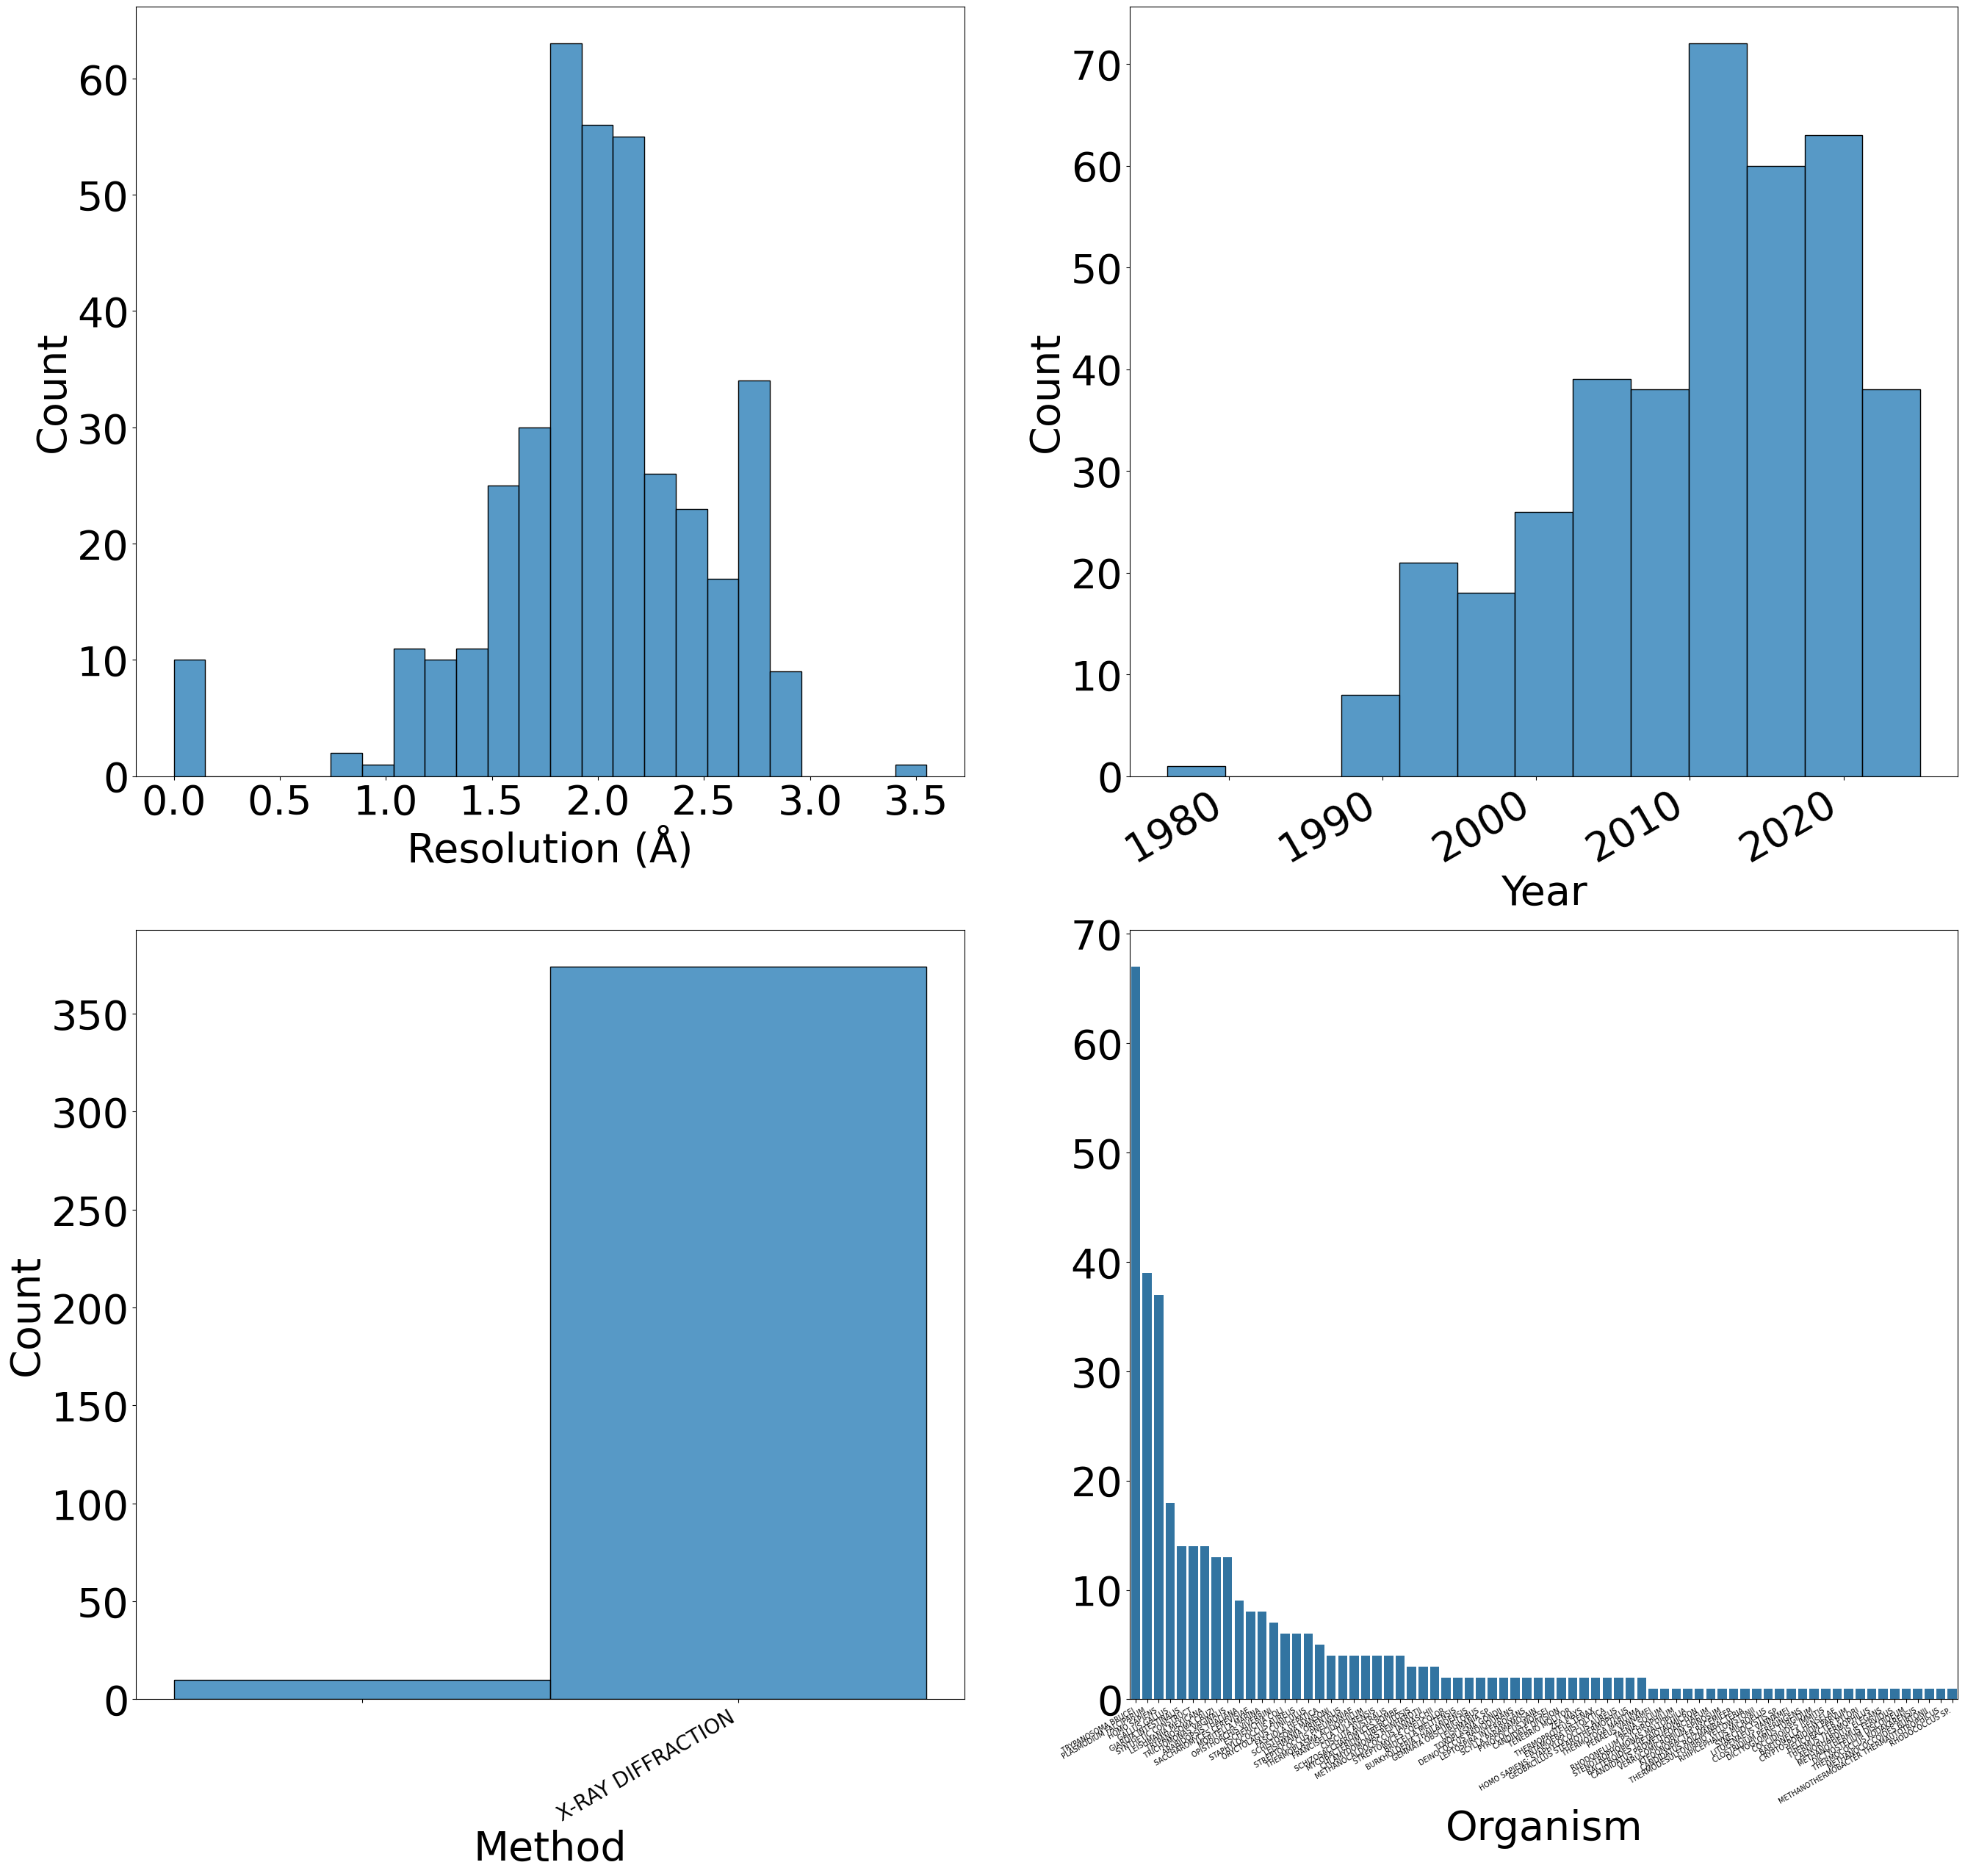

In [9]:
# Create images with the plots summarizing the info in the dataframe

summary_plots_pdbs(df, output_directory, org_name + '_RCSB')